In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [4]:
df = pd.read_csv("healthcare_dataset.csv")
df

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results
0,Bobby JacksOn,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.281306,328,Urgent,2024-02-02,Paracetamol,Normal
1,LesLie TErRy,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.327287,265,Emergency,2019-08-26,Ibuprofen,Inconclusive
2,DaNnY sMitH,76,Female,A-,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.096079,205,Emergency,2022-10-07,Aspirin,Normal
3,andrEw waTtS,28,Female,O+,Diabetes,2020-11-18,Kevin Wells,"Hernandez Rogers and Vang,",Medicare,37909.782410,450,Elective,2020-12-18,Ibuprofen,Abnormal
4,adrIENNE bEll,43,Female,AB+,Cancer,2022-09-19,Kathleen Hanna,White-White,Aetna,14238.317814,458,Urgent,2022-10-09,Penicillin,Abnormal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
55495,eLIZABeTH jaCkSOn,42,Female,O+,Asthma,2020-08-16,Joshua Jarvis,Jones-Thompson,Blue Cross,2650.714952,417,Elective,2020-09-15,Penicillin,Abnormal
55496,KYle pEREz,61,Female,AB-,Obesity,2020-01-23,Taylor Sullivan,Tucker-Moyer,Cigna,31457.797307,316,Elective,2020-02-01,Aspirin,Normal
55497,HEATher WaNG,38,Female,B+,Hypertension,2020-07-13,Joe Jacobs DVM,"and Mahoney Johnson Vasquez,",UnitedHealthcare,27620.764717,347,Urgent,2020-08-10,Ibuprofen,Abnormal
55498,JENniFER JOneS,43,Male,O-,Arthritis,2019-05-25,Kimberly Curry,"Jackson Todd and Castro,",Medicare,32451.092358,321,Elective,2019-05-31,Ibuprofen,Abnormal


In [5]:
df.shape


(55500, 15)

In [6]:
df.dtypes

Name                   object
Age                     int64
Gender                 object
Blood Type             object
Medical Condition      object
Date of Admission      object
Doctor                 object
Hospital               object
Insurance Provider     object
Billing Amount        float64
Room Number             int64
Admission Type         object
Discharge Date         object
Medication             object
Test Results           object
dtype: object

In [7]:
df.isnull().sum()

Name                  0
Age                   0
Gender                0
Blood Type            0
Medical Condition     0
Date of Admission     0
Doctor                0
Hospital              0
Insurance Provider    0
Billing Amount        0
Room Number           0
Admission Type        0
Discharge Date        0
Medication            0
Test Results          0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(534)

In [9]:
df.describe()

,Age,Billing Amount,Room Number
count,55500.000000,55500.000000,55500.000000
mean,51.539459,25539.316097,301.134829
std,19.602454,14211.454431,115.243069
min,13.000000,-2008.492140,101.000000
25%,35.000000,13241.224652,202.000000
50%,52.000000,25538.069376,302.000000
75%,68.000000,37820.508436,401.000000
max,89.000000,52764.276736,500.000000


In [12]:
df = df.drop_duplicates()
df.duplicated().sum()

np.int64(0)

In [16]:
df['Name'] = df['Name'].str.strip().str.title()
df.head()

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results
0,Bobby Jackson,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.281306,328,Urgent,2024-02-02,Paracetamol,Normal
1,Leslie Terry,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.327287,265,Emergency,2019-08-26,Ibuprofen,Inconclusive
2,Danny Smith,76,Female,A-,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.096079,205,Emergency,2022-10-07,Aspirin,Normal
3,Andrew Watts,28,Female,O+,Diabetes,2020-11-18,Kevin Wells,"Hernandez Rogers and Vang,",Medicare,37909.782410,450,Elective,2020-12-18,Ibuprofen,Abnormal
4,Adrienne Bell,43,Female,AB+,Cancer,2022-09-19,Kathleen Hanna,White-White,Aetna,14238.317814,458,Urgent,2022-10-09,Penicillin,Abnormal


In [19]:
df.loc[df['Billing Amount'] < 0, 'Billing Amount'] = df['Billing Amount'].mean()
df.describe()

,Age,Billing Amount,Room Number
count,54966.000000,54966.000000,54966.000000
mean,51.535185,25594.536582,301.124404
std,19.605661,14162.191537,115.223143
min,13.000000,9.238787,101.000000
25%,35.000000,13326.001350,202.000000
50%,52.000000,25544.306284,302.000000
75%,68.000000,37819.858159,401.000000
max,89.000000,52764.276736,500.000000


In [20]:
df['Date of Admission'] = pd.to_datetime(df['Date of Admission'])
df['Discharge Date'] = pd.to_datetime(df['Discharge Date'])

In [23]:
df['Length of Stay'] = (df['Discharge Date'] - df['Date of Admission']).dt.days
df.head()

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results,Length of Stay
0,Bobby Jackson,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.281306,328,Urgent,2024-02-02,Paracetamol,Normal,2
1,Leslie Terry,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.327287,265,Emergency,2019-08-26,Ibuprofen,Inconclusive,6
2,Danny Smith,76,Female,A-,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.096079,205,Emergency,2022-10-07,Aspirin,Normal,15
3,Andrew Watts,28,Female,O+,Diabetes,2020-11-18,Kevin Wells,"Hernandez Rogers and Vang,",Medicare,37909.782410,450,Elective,2020-12-18,Ibuprofen,Abnormal,30
4,Adrienne Bell,43,Female,AB+,Cancer,2022-09-19,Kathleen Hanna,White-White,Aetna,14238.317814,458,Urgent,2022-10-09,Penicillin,Abnormal,20


In [25]:
df.shape

(54966, 16)

In [28]:
medicalConditionCount = df['Medical Condition'].value_counts()
medicalConditionCount

Medical Condition
Arthritis       9218
Diabetes        9216
Hypertension    9151
Obesity         9146
Cancer          9140
Asthma          9095
Name: count, dtype: int64

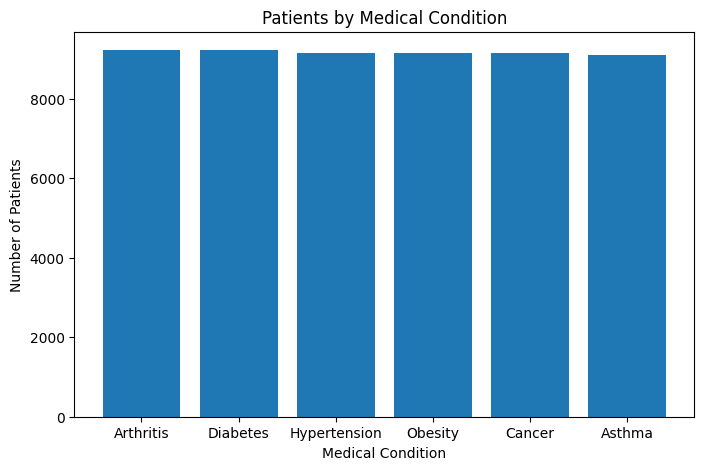

In [33]:
plt.figure(figsize = (8,5))
plt.bar(medicalConditionCount.index, medicalConditionCount.values)
plt.title("Patients by Medical Condition")
plt.xlabel("Medical Condition")
plt.ylabel("Number of Patients")

plt.show()

In [ ]:
averageAge = df['Age'].mean()
averageAge

np.float64(51.53518538733035)

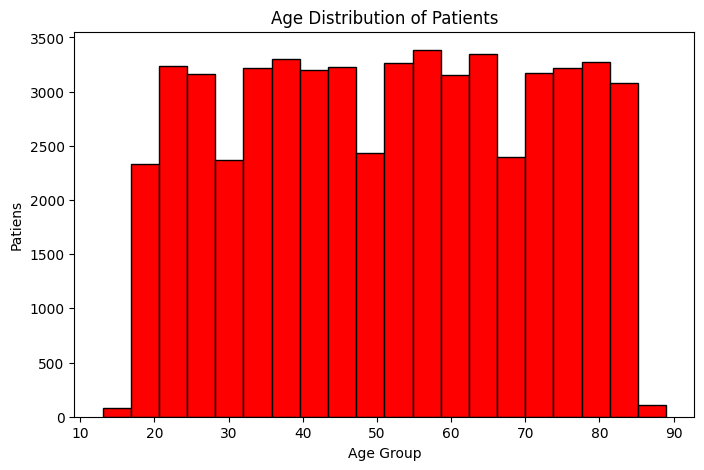

In [44]:
plt.figure(figsize = (8,5))
plt.hist(df['Age'], bins = 20, color = 'Red', edgecolor = 'Black')
plt.title("Age Distribution of Patients")
plt.ylabel("Patiens")
plt.xlabel("Age Group")
plt.show()


In [45]:
averageCost = df['Billing Amount'].mean()
averageCost

np.float64(25594.536582219524)

In [48]:
df['Admission Month'] = df['Date of Admission'].dt.to_period('M')
df.head()

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results,Length of Stay,Admission Month
0,Bobby Jackson,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.281306,328,Urgent,2024-02-02,Paracetamol,Normal,2,2024-01
1,Leslie Terry,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.327287,265,Emergency,2019-08-26,Ibuprofen,Inconclusive,6,2019-08
2,Danny Smith,76,Female,A-,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.096079,205,Emergency,2022-10-07,Aspirin,Normal,15,2022-09
3,Andrew Watts,28,Female,O+,Diabetes,2020-11-18,Kevin Wells,"Hernandez Rogers and Vang,",Medicare,37909.782410,450,Elective,2020-12-18,Ibuprofen,Abnormal,30,2020-11
4,Adrienne Bell,43,Female,AB+,Cancer,2022-09-19,Kathleen Hanna,White-White,Aetna,14238.317814,458,Urgent,2022-10-09,Penicillin,Abnormal,20,2022-09


In [50]:
monthlyAvg = df.groupby('Admission Month')['Billing Amount'].mean()
monthlyAvg

Admission Month
2019-05    25897.449655
2019-06    26324.004064
2019-07    25928.602371
2019-08    25457.102225
2019-09    24915.548929
               ...     
2024-01    25836.695757
2024-02    25703.588425
2024-03    25310.583403
2024-04    24930.033214
2024-05    25464.902913
Freq: M, Name: Billing Amount, Length: 61, dtype: float64

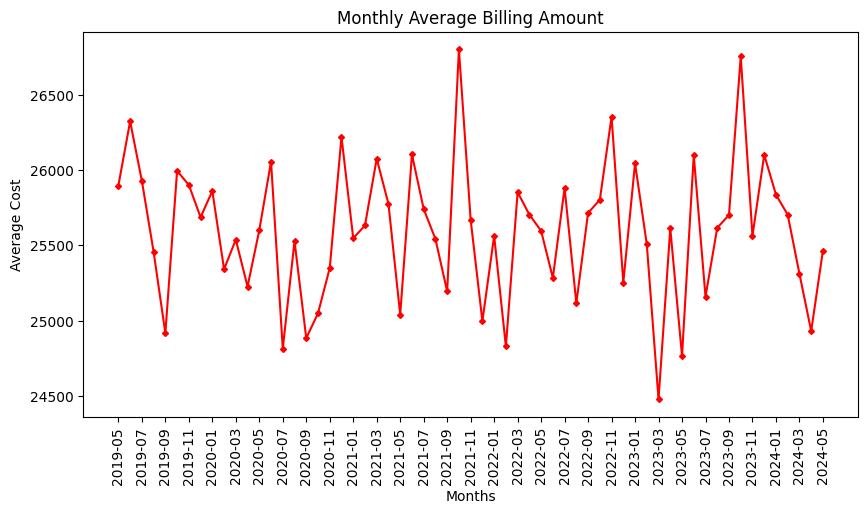

In [62]:
plt.figure(figsize = (10, 5))
plt.plot(monthlyAvg.index.astype(str), monthlyAvg.values, color = 'red', marker = 'D', markersize = 3)
plt.title("Monthly Average Billing Amount")
plt.xlabel("Months")
plt.ylabel("Average Cost")
plt.xticks(ticks=range(0, len(monthlyAvg), 2), rotation = 90)

plt.show()

In [64]:
seniorPatientAvgCost = df.loc[df['Age'] >= 60, 'Billing Amount'].mean()
seniorPatientAvgCost

np.float64(25563.58776383007)

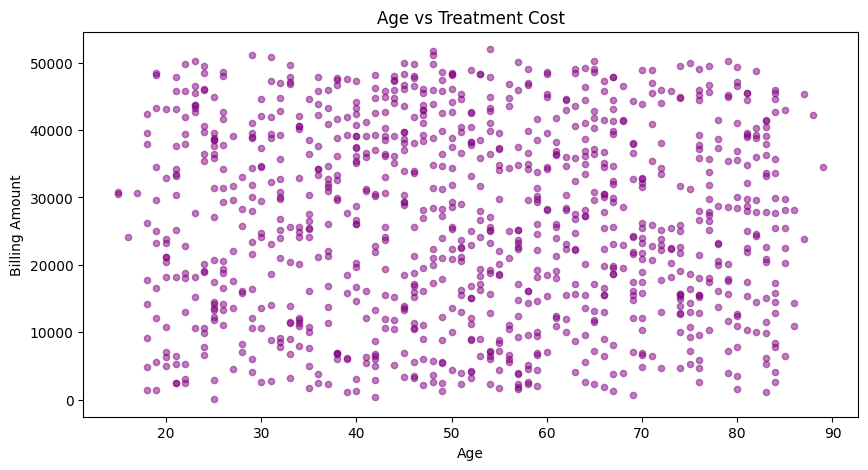

In [69]:
sample_df = df.sample(1000, random_state = 1)
plt.figure(figsize = (10,5))
plt.scatter(sample_df['Age'], sample_df['Billing Amount'], color = 'Purple', alpha = 0.5, s = 20)
plt.title("Age vs Treatment Cost")
plt.xlabel("Age")
plt.ylabel("Billing Amount")
plt.show()

In [72]:
insuranceCount = df['Insurance Provider'].value_counts()
insuranceCount

Insurance Provider
Cigna               11139
Medicare            11039
UnitedHealthcare    11014
Blue Cross          10952
Aetna               10822
Name: count, dtype: int64

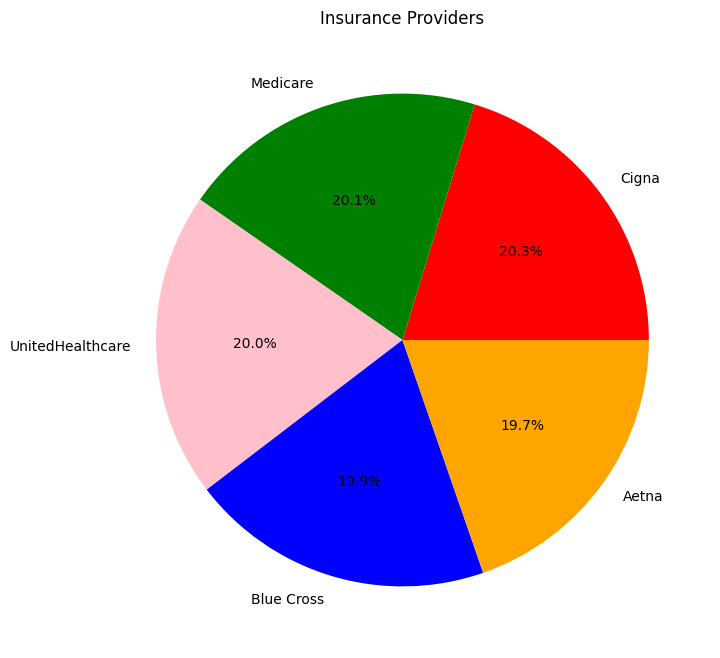

In [77]:
plt.figure(figsize = (8,8))
plt.pie(insuranceCount.values, labels = insuranceCount.index, autopct = '%1.1f%%', colors = ['Red', 'Green', 'Pink', 'Blue', 'Orange'])
plt.title("Insurance Providers")
plt.show()

In [78]:
df.head()

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results,Length of Stay,Admission Month
0,Bobby Jackson,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.281306,328,Urgent,2024-02-02,Paracetamol,Normal,2,2024-01
1,Leslie Terry,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.327287,265,Emergency,2019-08-26,Ibuprofen,Inconclusive,6,2019-08
2,Danny Smith,76,Female,A-,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.096079,205,Emergency,2022-10-07,Aspirin,Normal,15,2022-09
3,Andrew Watts,28,Female,O+,Diabetes,2020-11-18,Kevin Wells,"Hernandez Rogers and Vang,",Medicare,37909.782410,450,Elective,2020-12-18,Ibuprofen,Abnormal,30,2020-11
4,Adrienne Bell,43,Female,AB+,Cancer,2022-09-19,Kathleen Hanna,White-White,Aetna,14238.317814,458,Urgent,2022-10-09,Penicillin,Abnormal,20,2022-09


In [79]:
emergencyByMonth = (df.loc[df['Admission Type'] == "Emergency"].groupby(df['Date of Admission'].dt.month).size())
emergencyByMonth

Date of Admission
1     1547
2     1452
3     1528
4     1473
5     1533
6     1483
7     1573
8     1533
9     1500
10    1490
11    1462
12    1528
dtype: int64

In [80]:
highCostPatients = df.loc[df['Billing Amount'] > df['Billing Amount'].quantile(0.90)]
highCostPatients

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results,Length of Stay,Admission Month
5,Emily Johnson,36,Male,A+,Asthma,2023-12-20,Taylor Newton,Nunez-Humphrey,UnitedHealthcare,48145.110951,389,Urgent,2023-12-24,Ibuprofen,Normal,4,2023-12
7,Christina Martinez,20,Female,A+,Cancer,2021-12-28,Suzanne Thomas,"Powell Robinson and Valdez,",Cigna,45820.462722,277,Emergency,2022-01-07,Paracetamol,Inconclusive,10,2021-12
8,Jasmine Aguilar,82,Male,AB+,Asthma,2020-07-01,Daniel Ferguson,Sons Rich and,Cigna,50119.222792,316,Elective,2020-07-14,Aspirin,Abnormal,13,2020-07
30,Thomas Martinez,34,Male,B-,Asthma,2019-08-18,Jacob Huynh,Hart Ltd,Cigna,47909.128810,371,Urgent,2019-09-01,Ibuprofen,Inconclusive,14,2019-08
35,David Anderson,25,Female,AB+,Asthma,2021-01-07,Emma Allison,Sons and Cox,Medicare,45453.418546,228,Elective,2021-01-26,Lipitor,Abnormal,19,2021-01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
55446,Richard Moore,63,Female,B+,Hypertension,2021-11-17,Dr. Jacob Aguilar,Blevins Group,Aetna,47649.696638,304,Emergency,2021-12-09,Penicillin,Abnormal,22,2021-11
55465,Amanda Stevens,71,Female,O-,Asthma,2019-06-11,Jessica Ramirez,Sims-Henderson,Cigna,45597.476264,164,Urgent,2019-06-22,Ibuprofen,Inconclusive,11,2019-06
55467,Sandra Chen,62,Female,B+,Asthma,2022-06-03,Morgan Hess,Park Ltd,Aetna,48563.608920,269,Emergency,2022-06-06,Lipitor,Abnormal,3,2022-06
55470,Taylor Best,60,Male,A-,Asthma,2020-10-14,Tracy Nichols,"Hopkins and Neal Logan,",Cigna,48664.879041,187,Emergency,2020-10-21,Penicillin,Normal,7,2020-10
